In [1]:
print(1)


1


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# The file has no column names, so we give them ourselves:
# engine number, cycle, 3 operating settings, 21 sensors
cols = ["unit", "cycle", "setting_1", "setting_2", "setting_3"] + \
       [f"sensor_{i}" for i in range(1, 22)]

train = pd.read_csv("../data/raw/cmapss/train_FD001.txt",
                    sep=r"\s+", header=None, names=cols)

train.shape

(20631, 26)

In [3]:
train.head()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [4]:
# For each engine, the last cycle = the cycle where it failed
lifetime = train.groupby("unit")["cycle"].max()
lifetime.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

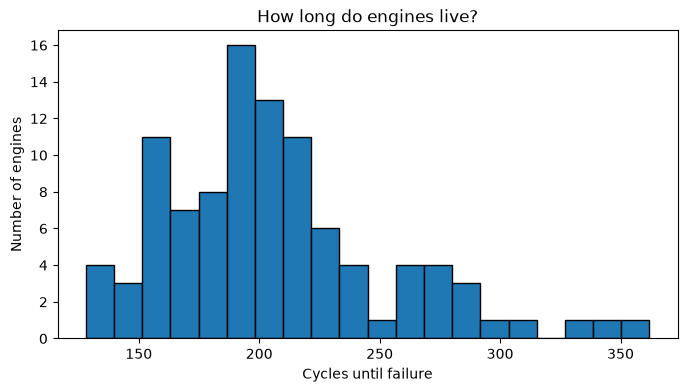

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(lifetime, bins=20, edgecolor="black")
plt.xlabel("Cycles until failure")
plt.ylabel("Number of engines")
plt.title("How long do engines live?")
plt.show()

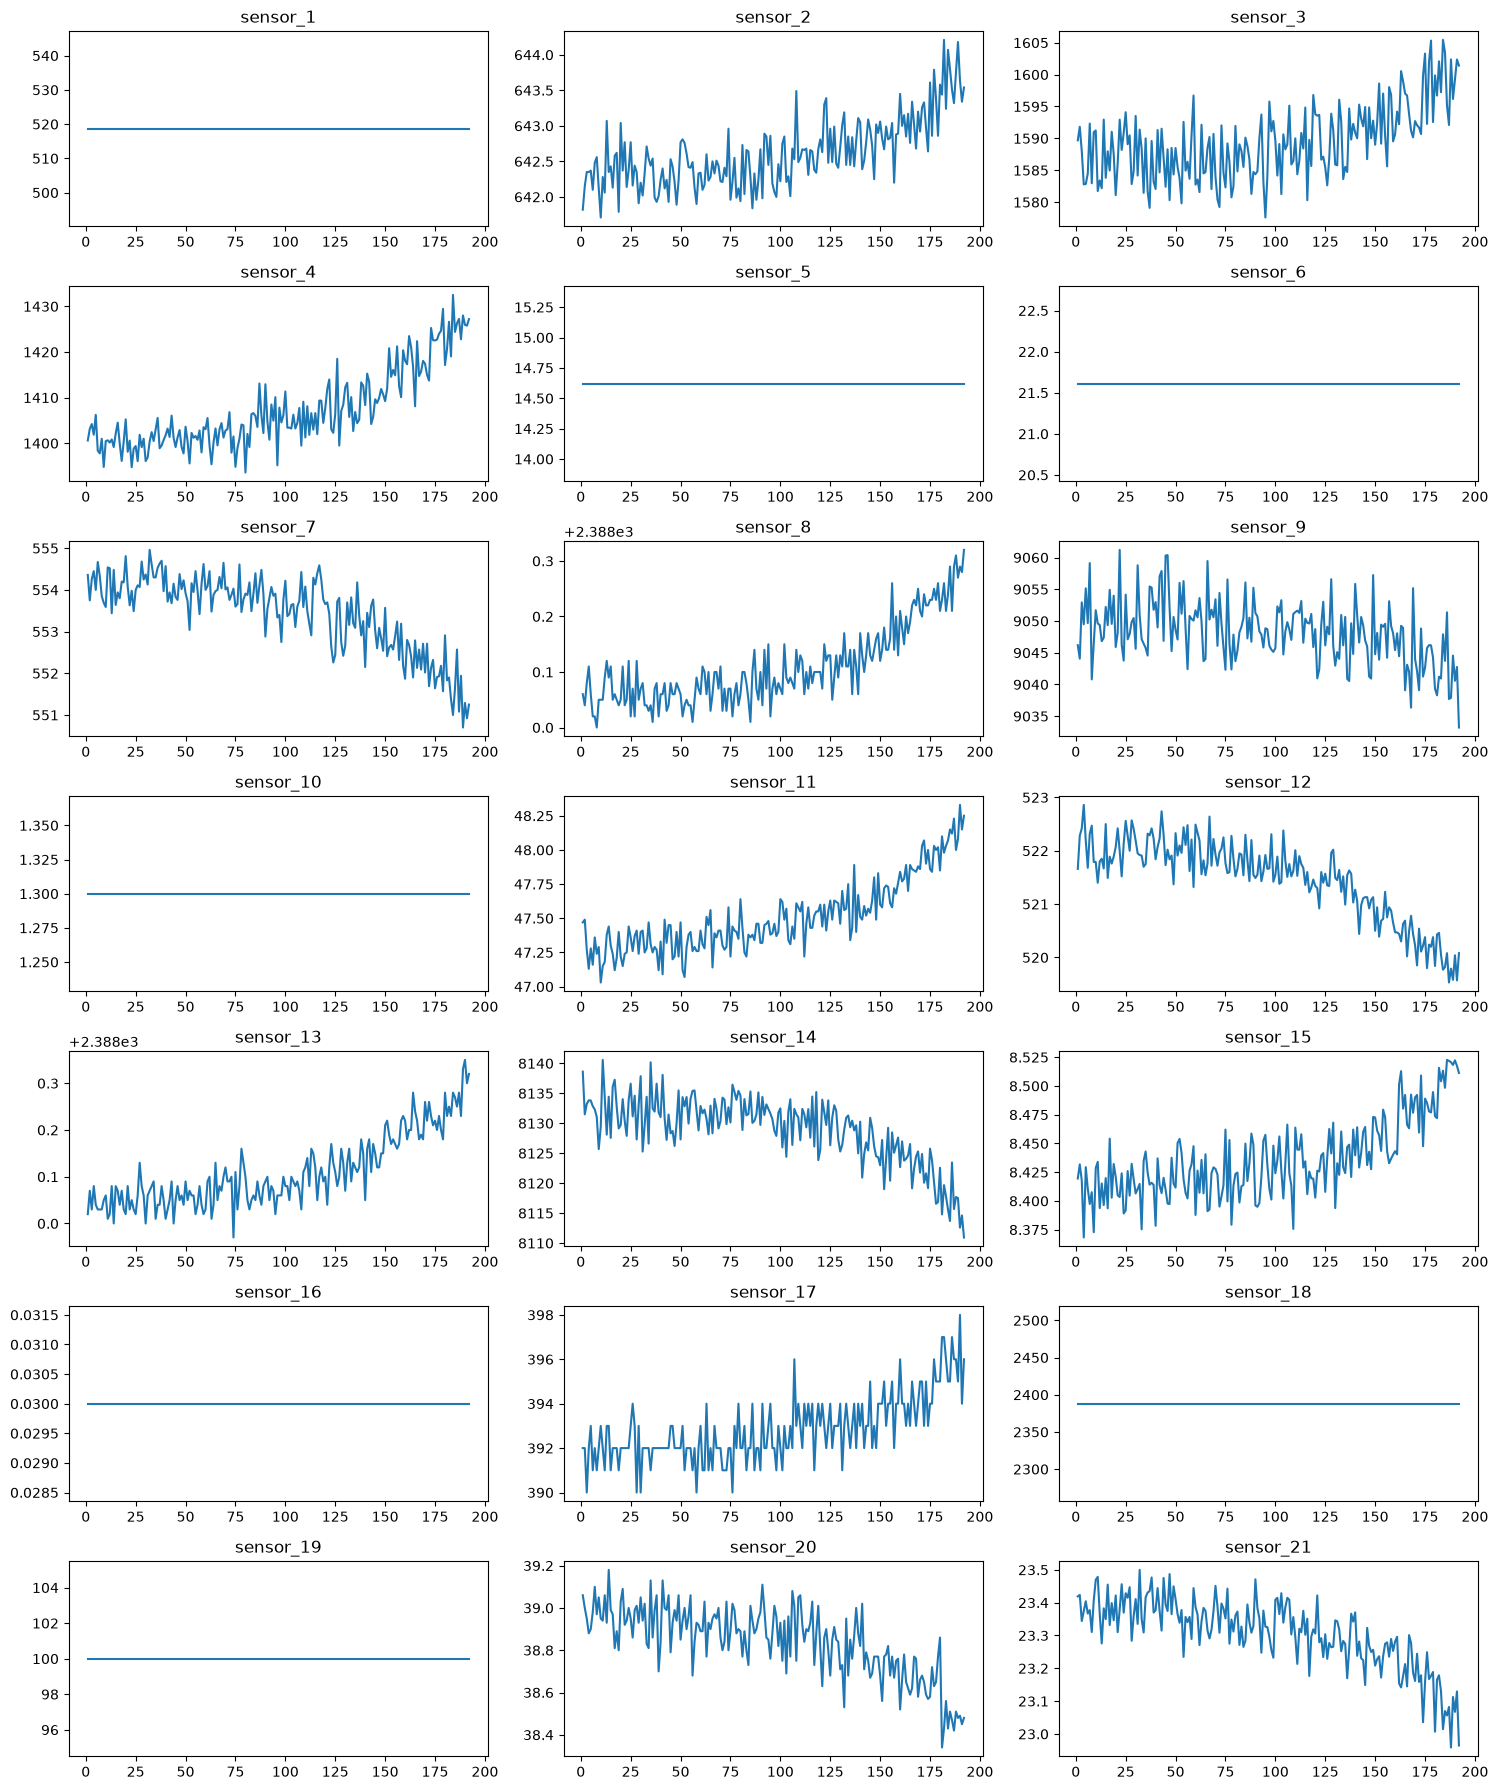

In [6]:
engine = train[train["unit"] == 1]

fig, axes = plt.subplots(7, 3, figsize=(15, 18))
for i, ax in enumerate(axes.flat):
    sensor = f"sensor_{i + 1}"
    ax.plot(engine["cycle"], engine[sensor])
    ax.set_title(sensor)
plt.tight_layout()
plt.show()

In [7]:
train.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
unit,51.506568,2.922763e+01,1.0000,100.0000
cycle,108.807862,6.888099e+01,1.0000,362.0000
setting_1,-0.000009,2.187313e-03,-0.0087,0.0087
setting_2,0.000002,2.930621e-04,-0.0006,0.0006
setting_3,100.000000,0.000000e+00,100.0000,100.0000
sensor_1,518.670000,0.000000e+00,518.6700,518.6700
sensor_2,642.680934,5.000533e-01,641.2100,644.5300
sensor_3,1590.523119,6.131150e+00,1571.0400,1616.9100
sensor_4,1408.933782,9.000605e+00,1382.2500,1441.4900
sensor_5,14.620000,5.329200e-15,14.6200,14.6200
